In [16]:
import sys
from pathlib import Path

project_root = Path("../../..").resolve()
sys.path.append(str(project_root))

import json
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from qiskit.circuit.library import EfficientSU2
from qiskit.primitives import StatevectorEstimator as Estimator
from qiskit_machine_learning.circuit.library import qnn_circuit
from qiskit_machine_learning.connectors import TorchConnector
from qiskit_machine_learning.gradients import SPSAEstimatorGradient
from qiskit_machine_learning.neural_networks import EstimatorQNN
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

from utils import DataManager
from utils.plotter import actual_vs_prediction


In [17]:
FAST_MODE = True          
USE_SPSA_IF_TRAINING = True  

NUM_QBITS = 4
ANSATZ_REPS = 1           
BATCH_SIZE = 128          
NUM_EPOCHS = 50

In [18]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device} (note: quantum layer runs on CPU regardless)")

Using device: cuda (note: quantum layer runs on CPU regardless)


In [19]:
qc, fm_params, anz_params = qnn_circuit(num_qubits=NUM_QBITS, ansatz=EfficientSU2(NUM_QBITS, reps=ANSATZ_REPS))

estimator = Estimator()

if not FAST_MODE and USE_SPSA_IF_TRAINING:
    gradient = SPSAEstimatorGradient(estimator=estimator, epsilon=0.01)
    estimator_qnn = EstimatorQNN(
        circuit=qc,
        input_params=fm_params,
        weight_params=anz_params,
        estimator=estimator,
        gradient=gradient,
        input_gradients=True,
    )
else:
    # FAST_MODE: no gradients needed at all since we detach + freeze
    estimator_qnn = EstimatorQNN(
        circuit=qc,
        input_params=fm_params,
        weight_params=anz_params,
        estimator=estimator,
        input_gradients=not FAST_MODE,
    )

print(f"Quantum layer trainable params: {len(anz_params)}  |  FAST_MODE={FAST_MODE}")


C:\Users\Clent\AppData\Local\Temp\ipykernel_4100\4205389470.py:1: DeprecationWarning: The class ``qiskit.circuit.library.n_local.efficient_su2.EfficientSU2`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.efficient_su2 instead.
  qc, fm_params, anz_params = qnn_circuit(num_qubits=NUM_QBITS, ansatz=EfficientSU2(NUM_QBITS, reps=ANSATZ_REPS))
No gradient function provided, creating a gradient function. If your Estimator requires transpilation, please provide a pass manager.


Quantum layer trainable params: 16  |  FAST_MODE=True


In [20]:
df = DataManager('bioactivity/vegfr2').dataset

with open('bioactivity_columns.json', 'r') as f:
    data = json.load(f)

df = df[data['columns']]
df = df.drop(columns=data['vegfr2_exclusion'])

X_df = df.drop(columns='pIC50')
y_df = df['pIC50']

X_train, X_test, y_train, y_test = train_test_split(X_df, y_df, test_size=0.2, random_state=25)

continuous_columns = [c for c in df.columns if not c.startswith("fp_") and c != "pIC50"]
binary_columns = [c for c in df.columns if c.startswith("fp_")]

df.columns


Index(['mol_weight', 'logp', 'tpsa', 'num_h_donors', 'num_h_acceptors',
       'num_rotatable_bonds', 'num_aromatic_rings', 'num_rings',
       'num_heavy_atoms', 'fraction_csp3',
       ...
       'fp_1015', 'fp_1016', 'fp_1017', 'fp_1018', 'fp_1019', 'fp_1020',
       'fp_1021', 'fp_1022', 'fp_1023', 'pIC50'],
      dtype='str', length=1034)

In [21]:
def scale_dataset(X_train, y_train, X_test=None, y_test=None):
    X_scaler = StandardScaler()
    y_scaler = StandardScaler()

    X_train_continuous = pd.DataFrame(
        X_scaler.fit_transform(X_train[continuous_columns]),
        columns=continuous_columns, index=X_train.index
    )
    X_train_binary = X_train[binary_columns].copy()
    X_train_processed = pd.concat([X_train_continuous, X_train_binary], axis=1)
    y_train_scaled = y_scaler.fit_transform(y_train.to_numpy().reshape(-1, 1))

    if X_test is not None:
        X_test_continuous = pd.DataFrame(
            X_scaler.transform(X_test[continuous_columns]),
            columns=continuous_columns, index=X_test.index
        )
        X_test_binary = X_test[binary_columns].copy()
        X_test_processed = pd.concat([X_test_continuous, X_test_binary], axis=1)
        y_test_scaled = y_scaler.transform(y_test.to_numpy().reshape(-1, 1))
        return X_train_processed, y_train_scaled, X_test_processed, y_test_scaled, X_scaler, y_scaler

    return X_train_processed, y_train_scaled, X_scaler, y_scaler

In [22]:
X_train_scaled, y_train_scaled, X_test_scaled, y_test_scaled, X_scaler, y_scaler = scale_dataset(
    X_train, y_train, X_test, y_test
)

X_train_tensor = torch.tensor(X_train_scaled.values, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled.values, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_scaled, dtype=torch.float32)

train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test_tensor, y_test_tensor), batch_size=BATCH_SIZE, shuffle=False)

In [23]:
class HybridQuantumClassicalRegressor(nn.Module):
    def __init__(self, in_channel, out_channel=1, drop_prob=0.2, hidden_dim=128, fast_mode=True):
        super().__init__()
        self.fast_mode = fast_mode

        self.fc1 = nn.Linear(in_channel, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, 64)
        self.norm1 = nn.LayerNorm(hidden_dim)
        self.norm2 = nn.LayerNorm(64)
        self.drop = nn.Dropout(drop_prob)

        self.quantum_layer = TorchConnector(estimator_qnn)
        if fast_mode:
            # freeze quantum weights entirely -- pure fixed feature map
            for p in self.quantum_layer.parameters():
                p.requires_grad = False

        self.regressor = nn.Sequential(
            nn.Linear(64 + estimator_qnn.output_shape[0], 16),
            nn.ReLU(),
            nn.Dropout(drop_prob),
            nn.Linear(16, out_channel)
        )

    def forward(self, x):
        x = self.fc1(x)
        x = self.norm1(x)
        x = F.relu(x)
        x = self.drop(x)

        x = self.fc2(x)
        x = self.norm2(x)
        x = F.relu(x)

        q_input = x[:, :NUM_QBITS]
        if self.fast_mode:
            # no gradient needs to flow through the quantum circuit at all
            q_out = self.quantum_layer(q_input.detach())
        else:
            q_out = self.quantum_layer(q_input)

        x = torch.cat([x, q_out], dim=1)
        return self.regressor(x)

In [24]:
model = HybridQuantumClassicalRegressor(
    in_channel=X_train_tensor.shape[1],
    out_channel=1,
    drop_prob=0.2,
    fast_mode=FAST_MODE,
).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    [p for p in model.parameters() if p.requires_grad],
    lr=1e-3, weight_decay=1e-4
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=15)


In [25]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss, total_samples = 0.0, 0
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        predictions = model(X_batch)
        loss = criterion(predictions, y_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        bs = X_batch.size(0)
        total_loss += loss.item() * bs
        total_samples += bs
    return total_loss / total_samples


def evaluate(model, loader, criterion, y_scaler, device):
    model.eval()
    total_loss, total_samples = 0.0, 0
    all_preds, all_targets = [], []
    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)
            bs = X_batch.size(0)
            total_loss += loss.item() * bs
            total_samples += bs
            all_preds.append(predictions.cpu())
            all_targets.append(y_batch.cpu())

    predictions = torch.cat(all_preds, dim=0).numpy()
    targets = torch.cat(all_targets, dim=0).numpy()
    predictions_original = y_scaler.inverse_transform(predictions)
    targets_original = y_scaler.inverse_transform(targets)

    mae = mean_absolute_error(targets_original, predictions_original)
    mse = mean_squared_error(targets_original, predictions_original)
    rmse = np.sqrt(mse)
    r2 = r2_score(targets_original, predictions_original)

    return {"y_pred": predictions_original, "loss": total_loss / total_samples,
            "mae": mae, "mse": mse, "rmse": rmse, "r2": r2}

In [26]:
best_r2 = -np.inf
best_state = None

for epoch in range(1, NUM_EPOCHS + 1):
    t0 = time.time()
    print(f"\n{'=' * 70}\nEpoch {epoch}/{NUM_EPOCHS}\n{'=' * 70}", flush=True)

    train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
    test_metrics = evaluate(model, test_loader, criterion, y_scaler, device)
    scheduler.step(test_metrics["loss"])

    current_r2 = test_metrics["r2"]
    if current_r2 > best_r2:
        best_r2 = current_r2
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"✓ New best model! R² = {best_r2:.6f}", flush=True)

    dt = time.time() - t0
    print(
        f"\nEpoch [{epoch:03d}/{NUM_EPOCHS}] | Train Loss: {train_loss:.6f} | "
        f"Test Loss: {test_metrics['loss']:.6f} | MAE: {test_metrics['mae']:.4f} | "
        f"RMSE: {test_metrics['rmse']:.4f} | R²: {current_r2:.4f} | Time: {dt:.1f}s",
        flush=True
    )

if best_state is not None:
    model.load_state_dict(best_state)
    print(f"\nBest model restored.\nBest Test R²: {best_r2:.6f}", flush=True)


Epoch 1/50
✓ New best model! R² = 0.325222

Epoch [001/50] | Train Loss: 0.852865 | Test Loss: 0.689104 | MAE: 0.6958 | RMSE: 0.8802 | R²: 0.3252 | Time: 6.1s

Epoch 2/50
✓ New best model! R² = 0.457516

Epoch [002/50] | Train Loss: 0.575853 | Test Loss: 0.554002 | MAE: 0.6128 | RMSE: 0.7892 | R²: 0.4575 | Time: 5.7s

Epoch 3/50
✓ New best model! R² = 0.513276

Epoch [003/50] | Train Loss: 0.435182 | Test Loss: 0.497057 | MAE: 0.5841 | RMSE: 0.7475 | R²: 0.5133 | Time: 5.7s

Epoch 4/50
✓ New best model! R² = 0.526723

Epoch [004/50] | Train Loss: 0.360823 | Test Loss: 0.483325 | MAE: 0.5712 | RMSE: 0.7371 | R²: 0.5267 | Time: 5.7s

Epoch 5/50
✓ New best model! R² = 0.564593

Epoch [005/50] | Train Loss: 0.294263 | Test Loss: 0.444651 | MAE: 0.5410 | RMSE: 0.7070 | R²: 0.5646 | Time: 5.7s

Epoch 6/50

Epoch [006/50] | Train Loss: 0.264528 | Test Loss: 0.467076 | MAE: 0.5523 | RMSE: 0.7246 | R²: 0.5426 | Time: 5.6s

Epoch 7/50
✓ New best model! R² = 0.573156

Epoch [007/50] | Train Loss

In [27]:
test_eval = evaluate(model, test_loader, criterion, y_scaler, device)

print(f'RMSE: {test_eval['rmse']}')
print(f'MSE: {test_eval['mse']}')
print(f'MAE: {test_eval['mae']}')
print(f'R2: {test_eval['r2']}')


RMSE: 0.6489554255641333
MSE: 0.42114314436912537
MAE: 0.47546902298927307
R2: 0.6331933736801147


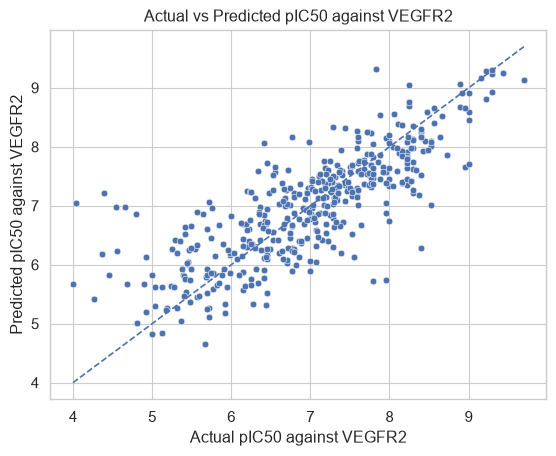

In [29]:
def to1D(data):
    return np.reshape(np.array(data), shape=(-1,))

actual_vs_prediction(y_test, to1D(test_eval['y_pred']), name="pIC50 against VEGFR2")